In [3]:
from torch.utils.data import DataLoader
import torch
from collections import OrderedDict
import numpy as np
import dataloader as dl

import sys
sys.path.append('../')
import irnet as ir

# Remove the parallelization from the model, making it usable with a single gpu and cpu
def remove_data_parallel(mod_name):
    state_dict = torch.load(mod_name, weights_only=True)
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        name = k.replace('module.', '')  # Remove 'module.' prefix
        new_state_dict[name] = v
    return new_state_dict

# Prepare the image for model input
def prepare_tensor(arr):
    if len(arr.shape) == 2:
        arr = arr[np.newaxis, np.newaxis, ...]
    elif len(arr.shape) == 3:
        arr = arr[np.newaxis, ...]
    
    return torch.tensor(arr).float()

# Detach the tensor and turn into numpy array
def detach_tensor(tsr):
    return tsr.detach().cpu().numpy()[0][0]

test_set = dl.HDRDataset(
                  input_dir= '../../../512-eevee-images/test/luminance',
                  gt_dir= '../../../512-eevee-images/test/albedo',
                  transforms=dl.transforms,
                  channels=1
    )

len(test_set)

5000

In [4]:
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

val_loader = DataLoader(test_set, batch_size=1, shuffle=False)
device = 'cuda'

all_out = []
all_gt = []

pixels = []
for i in range(5000):
    pixels.append(np.random.choice(262144, 1000, replace=False))

print(np.array(pixels).shape)
ps = np.random.choice(5000000, 1000, replace=False)

corrs = []
median_diffs = []  # Store median absolute differences
xs = []
ys = []

for run_num in range(1, 11):
    model_path = f"../model_weights/irnet-512-run{run_num}-v10.pt"
    model = ir.IRNet().to(device)
    model.load_state_dict(remove_data_parallel(model_path))

    mod_out = []
    gt_comp = []

    for i, (luminance, gt) in tqdm(enumerate(val_loader), total=len(val_loader), desc="Processing Test Images"):
        image = prepare_tensor(luminance)

        output = model(image.to(device))
        output = detach_tensor(output)
        gt = detach_tensor(gt)

        mod_out.append(output.flatten()[pixels[i]])
        gt_comp.append(gt.flatten()[pixels[i]])

    mod_out = np.concatenate(mod_out)
    gt_comp = np.concatenate(gt_comp)

    # Calculate correlation
    correlation, _ = pearsonr(gt_comp, mod_out)
    corrs.append(correlation)

    # Calculate Median Absolute Difference
    median_diff = np.median(np.abs(gt_comp - mod_out))
    median_diffs.append(median_diff)

    print(f"Run {run_num}: Correlation = {correlation:.4f}, Median Abs Difference = {median_diff:.4f}")

    x = gt_comp[ps]
    y = mod_out[ps]

    xs.append(x)
    ys.append(y)

print("All Correlation Scores:", corrs)
print("All Median Absolute Differences:", median_diffs)

(5000, 1000)


Processing Test Images:   0%|          | 0/5000 [00:00<?, ?it/s]

/tmp/ipykernel_35453/383961165.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(arr).float()


Run 1: Correlation = 0.8227, Median Abs Difference = 0.0736


Processing Test Images:   0%|          | 0/5000 [00:00<?, ?it/s]

Run 2: Correlation = 0.8207, Median Abs Difference = 0.0755


... (12 outputs left out)

Processing Test Images:   0%|          | 0/5000 [00:00<?, ?it/s]

Run 9: Correlation = 0.8098, Median Abs Difference = 0.0767


Processing Test Images:   0%|          | 0/5000 [00:00<?, ?it/s]

Run 10: Correlation = 0.7877, Median Abs Difference = 0.0829
All Correlation Scores: [0.82271284, 0.8207229, 0.82651186, 0.8065534, 0.7501304, 0.8269783, 0.7857933, 0.8274142, 0.80980647, 0.78773075]
All Median Absolute Differences: [0.07364038, 0.07553747, 0.07672858, 0.072013795, 0.09106523, 0.070406854, 0.08407013, 0.07037112, 0.07673329, 0.082906455]


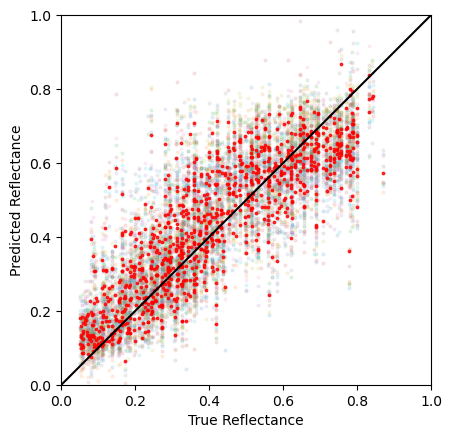

In [5]:
xs_arr = np.array(xs)
ys_arr = np.array(ys)

for i in range(10):
    plt.scatter(xs_arr[0], ys_arr[i], s=4, alpha=0.1)
plt.scatter(xs_arr[0], np.mean(ys_arr, axis=0), color='red', s=3, alpha=0.8)

plt.plot(np.linspace(0,1,100), np.linspace(0,1,100), color='black')
plt.xlabel('True Reflectance')
plt.ylabel('Predicted Reflectance')
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.gca().set_aspect('equal')
plt.show()

In [6]:
ref_dict = {
    'all_median_error': median_diffs, 
    'all_correlationss': corrs, 
    'gt_pixels': xs_arr[0], 
    'all_model_outputs': ys_arr
}

In [7]:
import pickle

with open('../data/testing.pickle', 'wb') as f:
    pickle.dump(ref_dict, f)


In [8]:
import pickle

with open('../data/testing.pickle', 'rb') as f:
    irn = pickle.load(f)

irn.keys()

dict_keys(['all_median_error', 'all_correlationss', 'gt_pixels', 'all_model_outputs'])